# 1.2

In [20]:
from neo4j import GraphDatabase
from getpass import getpass

In [11]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
# PW = getpass("Masukkan password Neo4j: ")
PW = "24031554098"
DB = "uts2"

driver = GraphDatabase.driver(URI, auth=(USER, PW))
driver.verify_connectivity()

print("Koneksi berhasil!")

Koneksi berhasil!


In [12]:
with driver.session(database=DB) as session:
    result = session.run("RETURN 1 AS tes")
    print(result.single()["tes"])

1


In [13]:
# 1.2.3 pembuatan sebuah Node berikut dengan relationship-nya.
def add_friends(driver,name,friends):
    with driver.session(database=DB) as session:
        session.run(
            "MERGE (n:Person {name: $name}) "
            "MERGE (f:Person {name: $friends}) "
            "MERGE (n)-[:KNOWS]->(f) ",
            name=name,friends=friends
        ).consume()
    print(f"Relasi {name} -> {friends} berhasil dibuat.")


In [14]:
# 1.2.4 mencetak dan menjalankan keseluruhan
def print_friends(driver, name):
    with driver.session(database=DB) as session:
        result= session.run(
            "MATCH (n:Person)-[:KNOWS]->(f) "
            "WHERE n.name = $name "
            "RETURN f.name as friends " 
            "ORDER BY friends",
            name=name
        )
        records = result
        print(f"daftra teman {name} :")
        for record in records:
            print(f'- {record["friends"]}')

In [15]:

# with GraphDatabase.driver(URI,auth=(USER,PW), ) as driver:
#     add_friends(driver,"Arthur", "Guinevere")
#     add_friends(driver,"Arthur", "Lancelot")
#     add_friends(driver,"Arthur", "Merlin")
#     print_friends(driver, "Arthur")

In [16]:
# jawaban tugas
with open("jawaban.txt", "r", encoding="utf-8") as file:
    jawaban = file.read()

print(jawaban)

1.
soal : apa nama database yang digunakan pada tutorial ini
jawab : DB = "uts"

2.
soal : sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan untuk mengakses database lain dalam 1 instance
jawab :
# untuk melihat daftar database (SHOW DATABASES;)
# contoh
SHOW DATABASES;

# memilih database yang akan digunakan (USE [nama_database])
# contoh
USE uts
RETURN 'Berhasil menggunakan database uts' AS pesan;

# melihat jumlah node di database terpilih
(USE [nama_database] MATCH (n) RETURN COUNT(n) as jumlah_node;)
# contoh
USE uts
MATCH (n)
RETURN COUNT(n) as jumlah_node;

# membuat database baru (CREATE DATABASE [nama_database])
# contoh
CREATE DATABASE test2;

# pindah ke database lain (USE[nama_database])
# contoh
USE test
RETURN 'Berhasil menggunakan database test' AS pesan;

# melihat node di database baru (USE [nama_database] MATCH (n) RETURN COUNT(n) as jumlah_node;)
# contoh
USE test
MATCH (n)
RETURN COUNT(n) as jumlah_node;

# hapus database (DROP DATABASE [nama

In [17]:
# with driver.session(database=DB) as session:
#     session.run(
#         "MATCH (n) "
#         "DETACH DELETE n"
#     ).consume()

# print("berhasil hapus.")

# 1.3

In [21]:
import zipfile
import os
import pandas as pd
import glob
import shutil
from tqdm.auto import tqdm
import argparse as ap
import sys

c:\Users\sholikin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1.3.1

In [23]:
zip_path = r"D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    for nama_file in zip_ref.namelist():
        print(nama_file)

ecommerce dataset/
ecommerce dataset/category_tree.csv
ecommerce dataset/events.csv
ecommerce dataset/item_properties_part1.csv
ecommerce dataset/item_properties_part2.csv


In [24]:


# Folder tujuan ekstraksi
extract_folder = r"D:\coding\coding semester 5\graf sains data\UTS"

# Buat folder tujuan jika belum ada
os.makedirs(extract_folder, exist_ok=True)

# Ekstrak semua file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Ekstraksi berhasil!")
print("Lokasi folder:", extract_folder)

# Tampilkan daftar file hasil ekstraksi
for nama_file in os.listdir(extract_folder):
    print(nama_file)

Ekstraksi berhasil!
Lokasi folder: D:\coding\coding semester 5\graf sains data\UTS
26_UTS-GSD.pdf
ecommerce dataset
ecommerce dataset.zip
jawaban.txt
main.py
myvenv
requirements.txt
soal 2.txt
uts.cypher
wrangling.ipynb
[ipynb]main.ipynb


In [26]:
os.remove(r"D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset.zip")

In [27]:
folder = r"D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset"
os.makedirs(folder, exist_ok=True)
folder_asal = r"D:\coding\coding semester 5\graf sains data\UTS"
folder_tujuan = os.path.join(folder_asal, "ecomers dataset")

os.makedirs(folder_tujuan, exist_ok=True)

file_data = (
    glob.glob(os.path.join(folder_asal, "*.csv")))

for file in file_data:
    shutil.move(file, folder_tujuan)

print("File berhasil dipindahkan.")

File berhasil dipindahkan.


In [28]:
import pandas as pd

# 1. Baca category_tree.csv
df_category = pd.read_csv(
    r"D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset\category_tree.csv"
)

# 2. Baca events.csv
df_events = pd.read_csv(
    r"D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset\events.csv"
)

# 3. Baca item_properties_part1.csv
df_item_properties1 = pd.read_csv(
    r"D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset\item_properties_part1.csv"
)

# 4. Baca item_properties_part2.csv
df_item_properties2 = pd.read_csv(
    r"D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset\item_properties_part2.csv"
)

# Tampilkan setiap DataFrame
print("======= category_tree.csv ===========")
display(df_category)
print()
print("======= events.csv ===========")
display(df_events)
print()
print("======= item_properties_part1 ===========")
display(df_item_properties1)
print()
print("======= item_properties_part2 ===========")
display(df_item_properties2)
print()

======= category_tree.csv ===========


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0
...,...,...
1664,49,1125.0
1665,1112,630.0
1666,1336,745.0
1667,689,207.0



======= events.csv ===========


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN
...,...,...,...,...,...
2756096,1438398785939,591435,view,261427,NaN
2756097,1438399813142,762376,view,115946,NaN
2756098,1438397820527,1251746,view,78144,NaN
2756099,1438398530703,1184451,view,283392,NaN



======= item_properties_part1 ===========


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513
...,...,...,...,...
10999994,1439694000000,86599,categoryid,618
10999995,1435460400000,153032,1066,n1020.000 424566
10999996,1440298800000,421788,888,35975 856003 37346
10999997,1437879600000,159792,400,n552.000 639502 n720.000 424566



======= item_properties_part2 ===========


,timestamp,itemid,property,value
0,1433041200000,183478,561,769062
1,1439694000000,132256,976,n26.400 1135780
2,1435460400000,420307,921,1149317 1257525
3,1431831600000,403324,917,1204143
4,1435460400000,230701,521,769062
...,...,...,...,...
9275898,1433646000000,236931,929,n12.000
9275899,1440903600000,455746,6,150169 639134
9275900,1439694000000,347565,686,610834
9275901,1433646000000,287231,867,769062


## 1.3.2

README
Perhatikan fitur yang telah diunduh dengan rincian sebagai berikut:
1. timestamp: Waktu dalam format unix epoch.
2. visitorid: ID unik pengunjung.
3. event: Jenis interaksi default: view, addtocart, transaction. (d) itemid: ID unik produk.
4. transactionid: ID transaksi, hanya terisi saat event berjenis ’transaction’.

In [29]:
df_list = [
    ("df_category", df_category),
    ("df_events", df_events),
    ("df_item_properties1", df_item_properties1),
    ("df_item_properties2", df_item_properties2)
]

for nama,df in df_list:
    print(f"==========={nama}==========")
    print(f"UKURAN DATASET : {df.shape}")
    df.info()
    display(df.isnull().sum())
    print()

===========df_category==========
UKURAN DATASET : (1669, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1669 entries, 0 to 1668
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   categoryid  1669 non-null   int64  
 1   parentid    1644 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 26.2 KB


categoryid     0
parentid      25
dtype: int64


===========df_events==========
UKURAN DATASET : (2756101, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64


===========df_item_properties1==========
UKURAN DATASET : (10999999, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999999 entries, 0 to 10999998
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   timestamp  int64 
 1   itemid     int64 
 2   property   object
 3   value      object
dtypes: int64(2), object(2)
memory usage: 335.7+ MB


timestamp    0
itemid       0
property     0
value        0
dtype: int64


===========df_item_properties2==========
UKURAN DATASET : (9275903, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9275903 entries, 0 to 9275902
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   timestamp  int64 
 1   itemid     int64 
 2   property   object
 3   value      object
dtypes: int64(2), object(2)
memory usage: 283.1+ MB


timestamp    0
itemid       0
property     0
value        0
dtype: int64

## 1.3.3 - 1.3.5

In [30]:
# 1.3.3
def parse_arguments():
    parser = ap.ArgumentParser(
        description="import RetailRocket (events.csv) ke database uts"
    )
    
    parser.add_argument(
         "-u",
         "--user",
         default="neo4j",
         help="username Neo4j"
     )
    parser.add_argument(
        "-p",
        "--password",
        default="",
        help="password Neo4j"
    )
    
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="URI conected Neo4j"
    )
    
    parser.add_argument(
       "-d",
       "--database",
       default="uts2",
       help="Nama database Neo4j" 
    )
    
    parser.add_argument(
        "-s",
        "--source",
        default=r"D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset",
        help="folder dataset"
    )
    return parser.parse_args(args=[])

args = parse_arguments()
print("Username:", args.user)
print("URI:", args.bolt)
print("Database:", args.database)
print("Folder dataset:", args.source)
    

Username: neo4j
URI: neo4j://127.0.0.1:7687
Database: uts2
Folder dataset: D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset


In [31]:
csv_file_path = os.path.join(args.source,"events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan")
    sys.exit(1)
try:
    driver = GraphDatabase.driver(
        args.bolt,auth=(args.user, PW)
    )
    driver.verify_connectivity()
    
except Exception as e:
    print(f"gagal terhubung ke database: {e}")
    sys.exit(1)

print(f"File ditemukan: {csv_file_path}")
print("Koneksi Neo4j berhasil!")

File ditemukan: D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset\events.csv
Koneksi Neo4j berhasil!


In [32]:
# 1.3.3 - Fungsi untuk impor data RetailRocket

# 1.3.3 - Fungsi untuk impor data RetailRocket

def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

    print("Constraint berhasil dibuat!")


def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'view'

        MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'addtocart'

        MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'transaction'

        MERGE (v)-[:BOUGHT {timestamp: row.timestamp,transactionId: row.transactionid}]->(i)
    }
    """

    tx.run(query, batch=batch)


In [42]:

# 1.3.4
batch_size = 10000
with driver.session(database=args.database) as session:
    create_constraints(session)
    print(f"membaca file dari: {csv_file_path}")
    
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    
    total_row = sum(1 for _ in open(csv_file_path, encoding="utf-8")) - 1
    total_chunks = (total_row// batch_size) + 1
    
    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks,desc="mengimpor bach data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch,records)
driver.close()
print("import berhasil")

Constraint berhasil dibuat!
membaca file dari: D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset\events.csv
Memulai proses impor data ke Neo4j...


mengimpor bach data: 100%|██████████| 276/276 [05:26<00:00,  1.18s/it]


import berhasil


In [33]:
with driver.session(database=DB) as session:
    result = session.run("""
        MATCH (v:Visitor)
        WITH count(v) AS totalVisitor
        MATCH (i:Item)
        WITH totalVisitor, count(i) AS totalItem
        MATCH ()-[r]->()
        RETURN
            totalVisitor,
            totalItem,
            count(r) AS totalRelationship
    """)

    data = result.single()

    print("Jumlah Visitor:", data["totalVisitor"])
    print("Jumlah Item:", data["totalItem"])
    print("Jumlah Relationship:", data["totalRelationship"])

Jumlah Visitor: 1407580
Jumlah Item: 235061
Jumlah Relationship: 2755644


# WRANGLING

In [34]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from tqdm.auto import tqdm
from scipy.sparse import coo_matrix
from sklearn.preprocessing import normalize

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama! (akan ditentukan)
Misal:P1 (18 Mei–31 Juli 2015) | P2 (01 Agt–18 Sept 2015)

In [35]:
df_events["datetime"] = pd.to_datetime(
    df_events["timestamp"],unit="ms",errors="coerce"
) 

# periode train and tesst
p1_start = "2015-05-18 00:00:00"
p1_end   = "2015-08-01 00:00:00"

p2_start = "2015-08-01 00:00:00"
p2_end   = "2015-09-19 00:00:00"

df_p1 = df_events[
    (df_events["datetime"] >= p1_start) & (df_events["datetime"]<p1_end)
].copy()

df_p2 = df_events[
    (df_events["datetime"] >= p2_start) & (df_events["datetime"] < p2_end)
].copy()

# hasil
print("=== PERIODE P1: TRAINING ===")
print("Jumlah data:", len(df_p1))
print("Tanggal awal:", df_p1["datetime"].min())
print("Tanggal akhir:", df_p1["datetime"].max())
print()
print("=== PERIODE P2: TESTING ===")
print("Jumlah data:", len(df_p2))
print("Tanggal awal:", df_p2["datetime"].min())
print("Tanggal akhir:", df_p2["datetime"].max())

=== PERIODE P1: TRAINING ===
Jumlah data: 1602710
Tanggal awal: 2015-05-18 00:00:01.025000
Tanggal akhir: 2015-07-31 23:59:58.354000

=== PERIODE P2: TESTING ===
Jumlah data: 857072
Tanggal awal: 2015-08-01 00:00:14.822000
Tanggal akhir: 2015-09-18 02:59:47.788000


2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [36]:
out_fol = os.path.join(args.source,'hasil_filter')
os.makedirs(out_fol,exist_ok=True)

p1_path = os.path.join(out_fol, "events_P1_training.csv")
p2_path = os.path.join(out_fol, "events_P2_testing.csv")

df_p1.to_csv(p1_path, index=False)
df_p2.to_csv(p2_path, index=False)


# Verifikasi hasil penyimpanan
print("=== HASIL PENYIMPANAN ===")
print("File P1:", p1_path)
print("Jumlah baris P1:", len(df_p1))
print("File P2:", p2_path)
print("Jumlah baris P2:", len(df_p2))
print()
print("File P1 berhasil dibuat:", os.path.exists(p1_path))
print("File P2 berhasil dibuat:", os.path.exists(p2_path))

=== HASIL PENYIMPANAN ===
File P1: D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset\hasil_filter\events_P1_training.csv
Jumlah baris P1: 1602710
File P2: D:\coding\coding semester 5\graf sains data\UTS\ecommerce dataset\hasil_filter\events_P2_testing.csv
Jumlah baris P2: 857072

File P1 berhasil dibuat: True
File P2 berhasil dibuat: True


In [37]:
print(df_p1.shape)
display(df_p1.isnull().sum())
display(df_p1.head())

(1602710, 6)


timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    1589658
datetime               0
dtype: int64

,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


In [38]:
print(df_p2.shape)
display(df_p2.isnull().sum())
display(df_p2.head())

(857072, 6)


timestamp             0
visitorid             0
event                 0
itemid                0
transactionid    850071
datetime              0
dtype: int64

,timestamp,visitorid,event,itemid,transactionid,datetime
610621,1438494458916,1190029,view,338463,NaN,2015-08-02 05:47:38.916
610622,1438494443158,1140512,view,184998,NaN,2015-08-02 05:47:23.158
610623,1438493656705,1111168,view,456909,NaN,2015-08-02 05:34:16.705
610624,1438495148775,938839,view,73918,NaN,2015-08-02 05:59:08.775
610625,1438494854924,505655,view,409804,NaN,2015-08-02 05:54:14.924


 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [39]:
import pandas as pd

query = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label AS jenis_node, count(*) AS jumlah_node
ORDER BY jenis_node
"""

with driver.session(database=DB) as session:
    node = session.run(query).data()

df_nodes = pd.DataFrame(node)

display(df_nodes)

,jenis_node,jumlah_node
0,Item,235061
1,Person,4
2,Visitor,1407580


## VSMberdasarkan user

4.  Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [40]:
p1_path = os.path.join(args.source,
    "hasil_filter","events_P1_training.csv"
)

df_p1 = pd.read_csv(p1_path,usecols=["visitorid", "itemid", "event"])
df_p1 = df_p1.dropna(subset=["visitorid", "itemid", "event"]).copy()

bobot_even = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

df_p1["weight"] =  df_p1["event"].map(bobot_even)
df_p1 = df_p1.dropna(subset=["weight"])

print(df_p1.shape)
print("Jumlah Visitor unik:", df_p1["visitorid"].nunique())
print("Jumlah Item unik:", df_p1["itemid"].nunique())
print()
print("Distribusi jenis interaksi:")
display(df_p1["event"].value_counts().to_frame("jumlah"))
print()
print("data p1:")
display(df_p1.head())

(1602710, 4)
Jumlah Visitor unik: 821515
Jumlah Item unik: 186336

Distribusi jenis interaksi:


,jumlah
event,
view,1550262
addtocart,39396
transaction,13052



data p1:


,visitorid,event,itemid,weight
0,257597,view,355908,1
1,992329,view,248676,1
2,111016,view,318965,1
3,483717,view,253185,1
4,951259,view,367447,1


In [41]:
# agregasi bobot 

df_inter = df_p1.groupby(["visitorid", "itemid"], as_index=False)["weight"].sum()

print("Jumlah pasangan (Visitor)->(Item):", len(df_inter))
print("Jumlah unik Visitor:", df_inter["visitorid"].nunique())
print("Jumlah unik Item:", df_inter["itemid"].nunique())
print()
print("Contoh hasil agregasi:")
display(df_inter.head(10))

Jumlah pasangan (Visitor)->(Item): 1246478
Jumlah unik Visitor: 821515
Jumlah unik Item: 186336

Contoh hasil agregasi:


,visitorid,itemid,weight
0,5,61396,1
1,8,434230,1
2,9,222422,1
3,13,278689,1
4,13,320589,1
5,14,330269,1
6,17,138434,1
7,19,84663,1
8,20,176623,1
9,22,86411,2


In [42]:
# membentuk sparse matrix
# visitor dan item sebagai index
vis = pd.Index(df_inter["visitorid"].unique())
item = pd.Index(df_inter["itemid"].unique())

# ubah vis dan item jadi baris kolom
row_idx = vis.get_indexer(df_inter["visitorid"])
col_idx = item.get_indexer(df_inter["itemid"])

# bentuk matrik
x_vis = coo_matrix(
    (df_inter["weight"].to_numpy(dtype=np.float32),(row_idx,col_idx)),
    shape =(len(vis), len(item)),
    dtype = np.float32
).tocsr()

# normalisasi
x_vis = normalize(x_vis, norm="l2", axis=1, copy=False)

print("Tipe matriks:", type(x_vis))
print("Dimensi matriks:", x_vis.ndim)
print("Shape matriks:", x_vis.shape)
print("Jumlah Visitor (baris):", x_vis.shape[0])
print("Jumlah Item (kolom):", x_vis.shape[1])
print("Jumlah nilai non-zero:", x_vis.nnz)
print("Total elemen jika dense:", x_vis.shape[0] * x_vis.shape[1])
print("Kerapatan matriks:", x_vis.nnz / (x_vis.shape[0] * x_vis.shape[1]))
print("Memori data sparse (MB):",
      (x_vis.data.nbytes +
       x_vis.indices.nbytes +
       x_vis.indptr.nbytes) / (1024**2))

Tipe matriks: <class 'scipy.sparse._csr.csr_matrix'>
Dimensi matriks: 2
Shape matriks: (821515, 186336)
Jumlah Visitor (baris): 821515
Jumlah Item (kolom): 186336
Jumlah nilai non-zero: 1246478
Total elemen jika dense: 153077819040
Kerapatan matriks: 8.142773445670069e-06
Memori data sparse (MB): 12.643707275390625


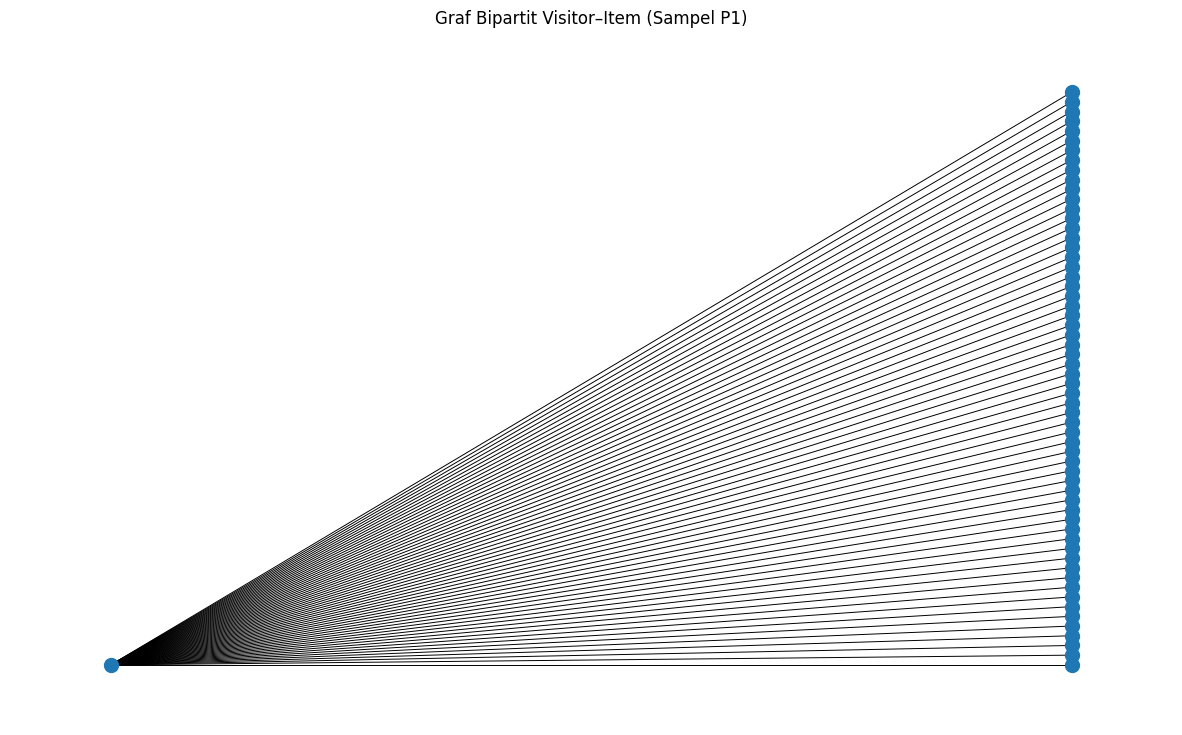

Jumlah node graf sampel: 61
Jumlah edge graf sampel: 60


In [43]:
#import networkx as nx
import matplotlib.pyplot as plt

# Ambil 15 Visitor dengan interaksi terbanyak
top_visitors = (
    df_inter.groupby("visitorid")["itemid"]
    .count()
    .sort_values(ascending=False)
    .head(15)
    .index
)

# Ambil interaksi milik Visitor terpilih
df_plot = df_inter[
    df_inter["visitorid"].isin(top_visitors)
].copy()

# Batasi jumlah Item agar visualisasi tetap terbaca
df_plot = df_plot.head(60)

# Buat graf bipartit Visitor-Item
G = nx.Graph()

visitor_nodes = [
    f"V_{v}" for v in df_plot["visitorid"].unique()
]
item_nodes = [
    f"I_{i}" for i in df_plot["itemid"].unique()
]

G.add_nodes_from(visitor_nodes, bipartite="visitor")
G.add_nodes_from(item_nodes, bipartite="item")

for _, row in df_plot.iterrows():
    G.add_edge(
        f"V_{row['visitorid']}",
        f"I_{row['itemid']}",
        weight=float(row["weight"])
    )

# Posisi node bipartit
pos = nx.bipartite_layout(
    G,
    nodes=visitor_nodes
)

plt.figure(figsize=(15, 9))

nx.draw_networkx(
    G,
    pos=pos,
    with_labels=False,
    node_size=100,
    width=0.7
)

plt.title("Graf Bipartit Visitor–Item (Sampel P1)")
plt.axis("off")
plt.show()

print("Jumlah node graf sampel:", G.number_of_nodes())
print("Jumlah edge graf sampel:", G.number_of_edges())

penjelasan

- matrik dibangun dengan kolom berisi item dan baris berisi visitor.
- matrik ini berdimensi 2dmiensi
- ukuran matrik ini adalah (821.515, 186.336)
- terdapat 1.246.478 sel yang berisi nilai bukan 0 setelah pasangan (visitor)(-)(item) terntegrasi
- total element matrik adalah 153.077.819.040. Ini diperoleh dari (821.515 x 186.336)
- kerapatan sangat rendah  hanya sekitar 0.0000814% sel yang terisi. artinya sebagian besar visitor hanya berinteraksi dengan sebagian kecil item (item dikunjungi banyak visitor,sehingga ada kemungkinan item yang sedikit / tidak pernah dikunjungi)
- tipe csr_matrik. Matriks menggunakan format Compressed Sparse Row dari SciPy, sehingga nilai nol tidak perlu disimpan satu per satu.
- visualisai graph menunjukan hubungan bipartit antara simpul Visitor dan Item. Setiap sisi merepresentasikan hubungan interaksi sesuai dengan konstruksi graf yang digunakan. dan terlihat 1 item bisa dikunjungi banyak visistor
- graf membandingkan Membandingkan pola interaksi Visitor

## VSM no 5 (item) -> (visitor)

5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)

In [44]:
# membentuk sparse matrix
# visitor dan item sebagai index
vis = pd.Index(df_inter["visitorid"].unique())
item = pd.Index(df_inter["itemid"].unique())

# ubah vis dan item jadi baris kolom
col_idx = vis.get_indexer(df_inter["visitorid"])
row_idx= item.get_indexer(df_inter["itemid"])

# bentuk matrik
x_item = coo_matrix(
    (df_inter["weight"].to_numpy(dtype=np.float32),(row_idx,col_idx)),
    shape =(len(item), len(vis)),
    dtype = np.float32
).tocsr()

# normalisasi
x_item = normalize(x_item, norm="l2", axis=1, copy=False)

print("Tipe matriks:", type(x_item))
print("Dimensi matriks:", x_item.ndim)
print("Shape matriks:", x_item.shape)
print("Jumlah item (baris):", x_item.shape[0])
print("Jumlah visitor (kolom):", x_item.shape[1])
print("Jumlah nilai non-zero:", x_item.nnz)
print("Total elemen jika dense:", x_item.shape[0] * x_item.shape[1])
print("Kerapatan matriks:", x_item.nnz / (x_item.shape[0] * x_item.shape[1]))
print("Memori data sparse (MB):",
      (x_item.data.nbytes +
       x_item.indices.nbytes +
       x_item.indptr.nbytes) / (1024**2))

Tipe matriks: <class 'scipy.sparse._csr.csr_matrix'>
Dimensi matriks: 2
Shape matriks: (186336, 821515)
Jumlah item (baris): 186336
Jumlah visitor (kolom): 821515
Jumlah nilai non-zero: 1246478
Total elemen jika dense: 153077819040
Kerapatan matriks: 8.142773445670069e-06
Memori data sparse (MB): 10.220691680908203


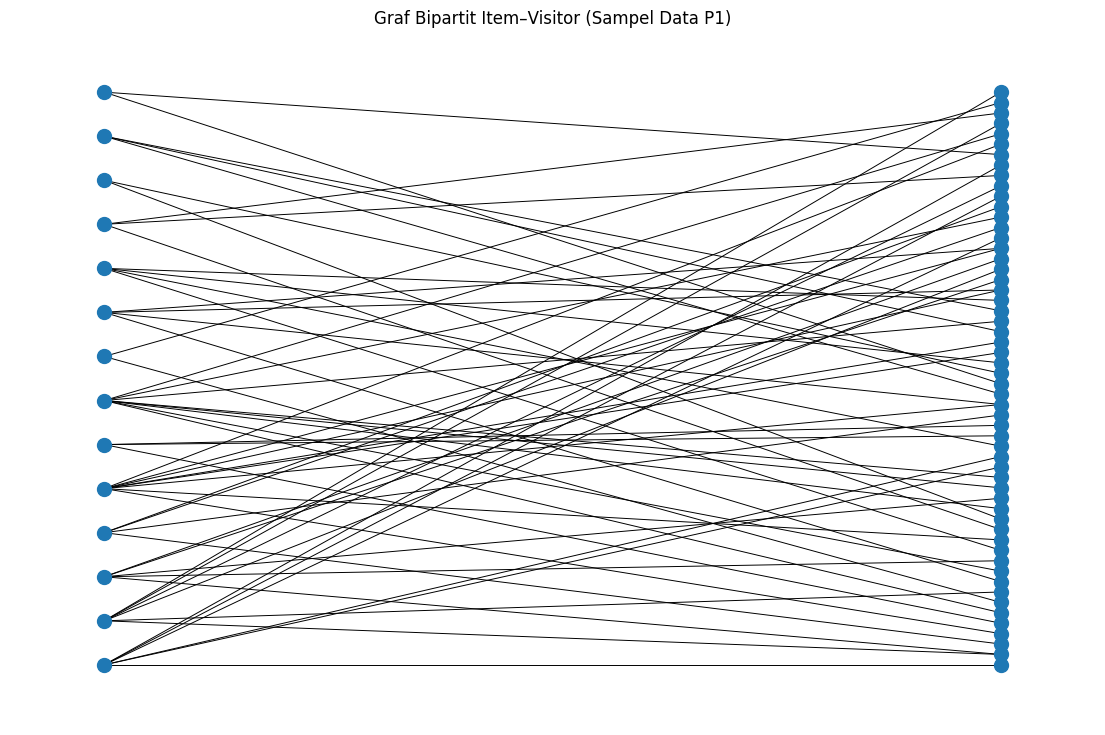

Jumlah node graf sampel: 70
Jumlah edge graf sampel: 60


In [45]:
import networkx as nx
import matplotlib.pyplot as plt

# Pilih 15 Item dengan jumlah interaksi terbanyak
top_items = (
    df_inter.groupby("itemid")["visitorid"]
    .count()
    .sort_values(ascending=False)
    .head(15)
    .index
)

# Ambil interaksi dari Item terpilih
df_plot = df_inter[
    df_inter["itemid"].isin(top_items)
].head(60).copy()

# Buat graf bipartit
G_item = nx.Graph()

item_nodes = [f"I_{i}" for i in df_plot["itemid"].unique()]
visitor_nodes = [f"V_{v}" for v in df_plot["visitorid"].unique()]

G_item.add_nodes_from(item_nodes, bipartite="item")
G_item.add_nodes_from(visitor_nodes, bipartite="visitor")

for _, row in df_plot.iterrows():
    G_item.add_edge(
        f"I_{row['itemid']}",
        f"V_{row['visitorid']}",
        weight=float(row["weight"])
    )

# Atur posisi Item dan Visitor pada dua sisi
pos = nx.bipartite_layout(G_item, nodes=item_nodes)

plt.figure(figsize=(14, 9))
nx.draw_networkx(
    G_item,
    pos=pos,
    with_labels=False,
    node_size=100,
    width=0.7
)

plt.title("Graf Bipartit Item–Visitor (Sampel Data P1)")
plt.axis("off")
plt.show()

print("Jumlah node graf sampel:", G_item.number_of_nodes())
print("Jumlah edge graf sampel:", G_item.number_of_edges())

- dimensi matrik ini adalah 2 dimensi
- dengan shape = (186336, 821515)
- baris merepresentasikan Item dan kolom merepresentasikan Visitor.
- terdapat 1.246.478: jumlah sel yang berisi nilai bukan nol setelah agregasi
- Total elemen dense = 153.077.819.040 (hasil perkalian jumlah baris dengan jumlah kolom)
- keraapatan rendah sama pada kasus soal 4
- graph Membandingkan pola interaksi Item
- Menemukan Item yang memiliki pola pengunjung serupa

VSM Item memiliki keunggulan untuk sistem rekomendasi berbasis kemiripan barang karena setiap Item direpresentasikan berdasarkan pola interaksinya dengan Visitor. Dengan demikian, sistem dapat menghitung kemiripan antar-Item dan merekomendasikan barang yang memiliki pola pengunjung serupa. Selain itu, jumlah baris VSM Item lebih sedikit daripada VSM Visitor, yaitu 186.336 dibandingkan 821.515, sehingga berpotensi mengurangi beban perhitungan untuk operasi yang membandingkan antarsimpul Item. Meskipun demikian, efisiensi aktual tetap bergantung pada algoritma, struktur matriks, dan operasi yang digunakan. VSM Visitor tetap lebih sesuai apabila tujuan analisisnya adalah menemukan pengunjung dengan pola perilaku yang serupa.

## lanjut 6-7-8

 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)

berdasarkan analisis dari soal 4 dan 5 , proyeksi item lebih sesuai untuk sistem rekomendasi berbasi barang. Proyeksi Visitor memiliki shape (821.515, 186.336), sedangkan proyeksi Item memiliki shape (186.336, 821.515). kuduanya memiliki  1.246.478 nilai non-zero dan kerapatan sekitar 0,000814%, karena karena merepresentasikan pasangan interaksi yang sama dengan orientasi matriks berbeda.

dari jumlah bsimpul, proyeksi item memiliki lenih sedikit baris karea jumlah ite,m lebih sedikit dari visitor . selain itu ,hasil pengukuran menunjukan bahwa memori yang akan terpakai lebih rendah.

Dengan demikian, proyeksi Item dipilih untuk analisis similarity menggunakan cosine similarity dan rekomendasi barang karena lebih sesuai dengan tujuan menemukan Item yang memiliki pola interaksi serupa. Sementara itu, proyeksi Visitor tetap bermanfaat untuk menemukan pengguna dengan pola perilaku yang mirip. Keunggulan efisiensi komputasi secara keseluruhan masih perlu dikonfirmasi melalui pengukuran waktu eksekusi dan memori total.

jika dilihat dari  visualisasi graf pada hasil nomor 4 dan 5, kedua graf merepresentasikan hubungan bipartit antara Visitor dan Item, tetapi memiliki arah analisis yang berbeda. Graf Visitor lebih memudahkan analisis perilaku pengguna berdasarkan barang yang diakses,  graf Item lebih memudahkan analisis pola pengunjung yang berinteraksi dengan barang tertentu.
Untuk tujuan sistem rekomendasi berbasis kemiripan barang, graf Item lebih relevan karena mendukung pencarian Item dengan pola interaksi serupa.

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python
   - Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!
   - Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [46]:
# Pilih Item acuan secara reproducible:
# Item dengan jumlah interaksi Visitor terbanyak
item_count = df_inter.groupby("itemid")["visitorid"].count()

anchor_item_id = item_count.idxmax()
anchor_idx = item.get_loc(anchor_item_id)

print(f"Item acuan: '''{anchor_item_id}'''")
print("Jumlah interaksi:", item_count.loc[anchor_item_id])

# similarity
sim_score = (x_item @ x_item[anchor_idx].T).toarray().ravel()

# Hilangkan Item acuan itu sendiri
sim_score[anchor_idx] = -1

# top 5 similarity
top = np.argsort(sim_score)[-5:][::-1]

df_top = pd.DataFrame({
    "item_acuan": anchor_item_id,
    "item_mirip": item.to_numpy()[top],
    "cosine_similarity": sim_score[top]
})
print()
print("Top 5 Item paling mirip:")
display(df_top)

Item acuan: '''5411'''
Jumlah interaksi: 1650

Top 5 Item paling mirip:


,item_acuan,item_mirip,cosine_similarity
0,5411,33030,0.153502
1,5411,33956,0.108333
2,5411,37807,0.101317
3,5411,459936,0.089384
4,5411,256242,0.086532


In [207]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt



# HITUNG TOP 5 ITEM

def top5(itemid):
    itemid = int(itemid)

    if itemid not in item:
        raise ValueError(
            f"Item {itemid} tidak ditemukan di matriks x_item."
        )

    anchor_idx = item.get_loc(itemid)

    # Hitung jumlah interaksi per Item
    item_count = df_inter.groupby("itemid")["visitorid"].count()

    # Hitung cosine similarity
    sim_score = (
        x_item @ x_item[anchor_idx].T
    ).toarray().ravel()

    # Keluarkan Item acuan sendiri
    sim_score[anchor_idx] = -1

    # Ambil Top 5
    top = np.argsort(sim_score)[-5:][::-1]

    df_top = pd.DataFrame({
        "item_acuan": itemid,
        "item_mirip": item.to_numpy()[top],
        "cosine_similarity": sim_score[top]
    })

    print(f"Item acuan: {itemid}")
    print("Jumlah interaksi:", item_count.get(itemid, 0))
    display(df_top)

    return df_top



# KIRIM TOP 5 KE NEO4J SEBAGAI EDGE
def graph(df_top):
    records = [
        {
            "item_acuan": int(row.item_acuan),
            "item_mirip": int(row.item_mirip),
            "cosine_similarity": float(row.cosine_similarity)
        }
        for row in df_top.itertuples(index=False)
    ]

    query = """
    UNWIND $rows AS row

    MATCH (a:Item {itemId: row.item_acuan})
    MATCH (b:Item {itemId: row.item_mirip})

    MERGE (a)-[r:SIMILAR_TO]->(b)
    SET r.cosine_similarity = row.cosine_similarity

    RETURN
        a.itemId AS item_acuan,
        b.itemId AS item_mirip,
        r.cosine_similarity AS similarity
    ORDER BY similarity DESC
    """

    with driver.session(database="uts2") as session:
        result = session.run(query, rows=records)
        df_hasil = pd.DataFrame(
            [dict(record) for record in result]
        )

    print("Hasil penyimpanan similarity ke Neo4j:")
    display(df_hasil)

    return df_hasil

# AMBIL EDGE DARI NEO4J DAN TAMPILKAN GRAF
def graphs(itemid):
    query = """
    MATCH (a:Item {itemId: $itemid})
          -[r:SIMILAR_TO]->(b:Item)
    RETURN
        a.itemId AS item_acuan,
        b.itemId AS item_mirip,
        r.cosine_similarity AS similarity
    ORDER BY similarity DESC
    LIMIT 5
    """

    with driver.session(database="uts2") as session:
        records = [
            dict(record)
            for record in session.run(query, itemid=int(itemid))
        ]

    if not records:
        print("Belum ada relasi SIMILAR_TO untuk Item ini.")
        return pd.DataFrame()

    # Bentuk graf berarah
    G = nx.DiGraph()

    for row in records:
        G.add_edge(
            row["item_acuan"],
            row["item_mirip"],
            weight=row["similarity"]
        )

    # Atur posisi node
    pos = nx.spring_layout(G, seed=42)

    # Gambar graf
    plt.figure(figsize=(12, 7))
    nx.draw_networkx(
        G,
        pos,
        with_labels=True,
        node_size=2200,
        font_size=9,
        arrows=True
    )

    # Tampilkan nilai similarity pada setiap edge
    edge_labels = {
        (u, v): f'{data["weight"]:.4f}'
        for u, v, data in G.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=8
    )

    plt.title(f"Top 5 Similar Items dari Item {itemid}")
    plt.axis("off")
    plt.show()

    return pd.DataFrame(records)



# JALANKAN SEMUA PROSES

def tampilkan(itemid):
    # 1. Hitung Top 5 Item paling mirip
    df_top = top5(itemid)

    # 2. Simpan similarity secara permanen ke Neo4j
    df_tersimpan = graph(df_top)

    # 3. Ambil relasi dari Neo4j dan visualisasikan
    hasil_graf = graphs(itemid)

    return df_top, df_tersimpan, hasil_graf

Item acuan: 222422
Jumlah interaksi: 61


,item_acuan,item_mirip,cosine_similarity
0,222422,247784,0.233955
1,222422,112129,0.214087
2,222422,372397,0.212579
3,222422,232725,0.211695
4,222422,285400,0.196875


Hasil penyimpanan similarity ke Neo4j:


,item_acuan,item_mirip,similarity
0,222422,247784,0.233955
1,222422,112129,0.214087
2,222422,372397,0.212579
3,222422,232725,0.211695
4,222422,285400,0.196875


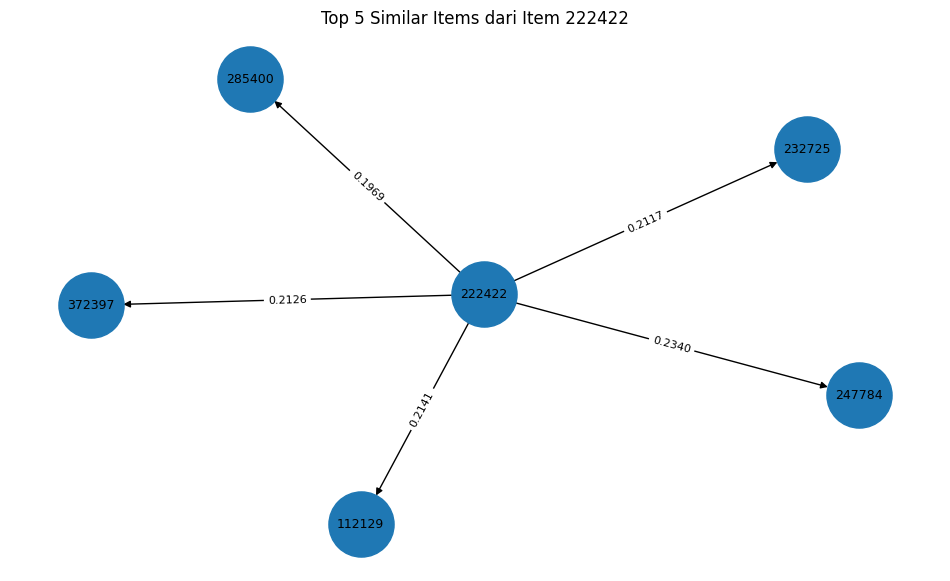

In [208]:
df_top, df_tersimpan, hasil_graf = tampilkan(222422)

MATCH (a:Item {itemId: 222422})
      -[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_mirip,
    r.cosine_similarity AS similarity
ORDER BY similarity DESC
LIMIT 5;

jika ingin menapilkan tabelnya (tabel top 5 rekomendasi ) maka pakai queri berikut 
text
```
MATCH (a:Item {itemId: 222422})
      -[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_mirip,
    r.cosine_similarity AS similarity
ORDER BY similarity DESC
LIMIT 5;
```

jika hendak mlihat grapnya pakai query
text
```
MATCH (a:Item {itemId: 222422})
      -[r:SIMILAR_TO]->(b:Item)
WITH a, r, b
ORDER BY r.cosine_similarity DESC
LIMIT 5
RETURN a, r, b;
```

hasilnya seperti berikut

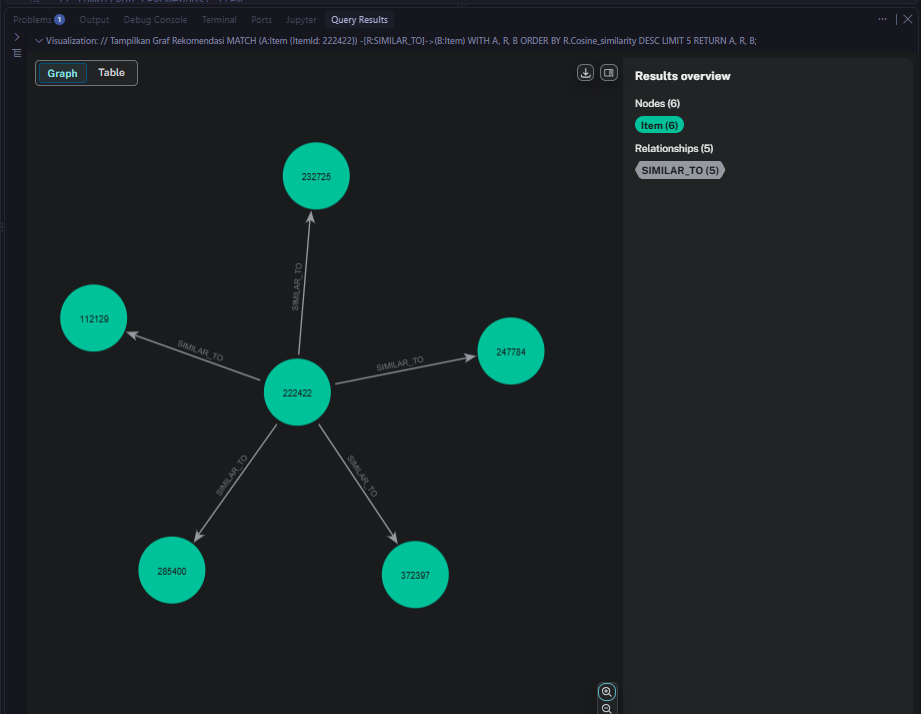

7.b



bagian cyper query yang menyimpan nilai sim ke neo4j adalah:
text
```
UNWIND $rows AS row
MATCH (a:Item {itemId: row.item_acuan})
MATCH (b:Item {itemId: row.item_mirip})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.cosine_similarity = row.cosine_similarity
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_mirip,
    r.cosine_similarity AS similarity
ORDER BY similarity DESC;
```

lalu menampilkan hasil ya di neo4j pakai query berikut 
text
```
MATCH (a:Item {itemId: 222422})
      -[r:SIMILAR_TO]->(b:Item)
RETURN
    a, r, b,
    r.cosine_similarity AS similarity
ORDER BY similarity DESC
LIMIT 5;
```

8.  Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [62]:
# Sebelum similarity
query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v, r, i
LIMIT 100
"""

with driver.session(database="uts2") as session:
    result = session.run(query)
    records = list(result)

# Ambil atribut node dan relasi agar mudah dibaca dalam tabel
df_asim = pd.DataFrame([
    {
        "visitorId": record["v"]["visitorId"],
        "jenis_interaksi": record["r"].type,
        "itemId": record["i"]["itemId"]
    }
    for record in records
])

display(df_asim.head(10))

,visitorId,jenis_interaksi,itemId
0,257597,VIEWED,355908
1,981382,VIEWED,355908
2,1102250,VIEWED,355908
3,62710,VIEWED,355908
4,76757,VIEWED,355908
5,979686,VIEWED,355908
6,479732,VIEWED,355908
7,397425,VIEWED,355908
8,1080757,VIEWED,355908
9,901216,VIEWED,355908


In [61]:
display(df_asim.head(10))

""


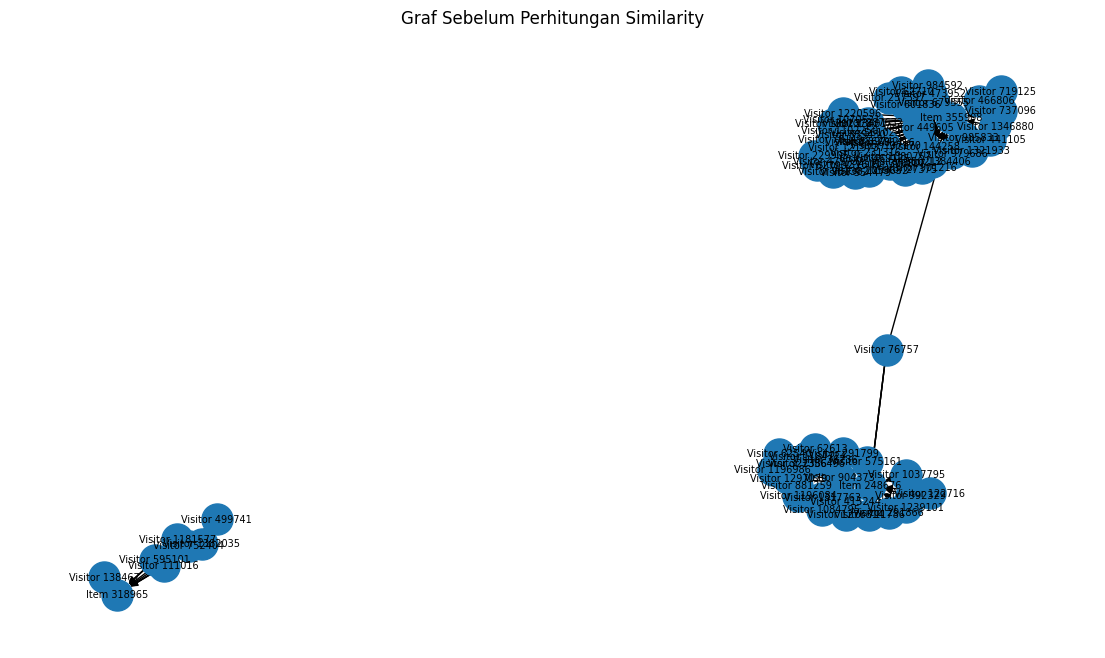

Jumlah node: 79
Jumlah edge: 100


In [57]:
# grafik sebelum sim_score
G = nx.MultiDiGraph()

for record in records:
    visitor_id = record["v"]["visitorId"]
    item_id = record["i"]["itemId"]
    event_type = record["r"].type

    G.add_edge(
        f"Visitor {visitor_id}",
        f"Item {item_id}",
        jenis=event_type
    )

# Tampilkan graf
plt.figure(figsize=(14, 8))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G, pos,
    with_labels=True,
    node_size=500,
    font_size=7,
    arrows=True
)

plt.title("Graf Sebelum Perhitungan Similarity")
plt.axis("off")
plt.show()

print("Jumlah node:", G.number_of_nodes())
print("Jumlah edge:", G.number_of_edges())

In [58]:
# sesudah sim
query = """
UNWIND [
    {item_mirip: 33030, similarity: 0.153502},
    {item_mirip: 33956, similarity: 0.108333},
    {item_mirip: 37807, similarity: 0.101317},
    {item_mirip: 459936, similarity: 0.089384},
    {item_mirip: 256242, similarity: 0.086532}
] AS row

MATCH (a:Item {itemId: 5411})
MATCH (b:Item {itemId: row.item_mirip})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.cosine_similarity = row.similarity

RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       r.cosine_similarity AS similarity
ORDER BY similarity DESC
"""

with driver.session(database=DB) as session:
    result = session.run(query)
    df_similarity = pd.DataFrame([dict(record) for record in result])

display(df_similarity)

,item_acuan,item_mirip,similarity
0,5411,33030,0.153502
1,5411,33956,0.108333
2,5411,37807,0.101317
3,5411,459936,0.089384
4,5411,256242,0.086532


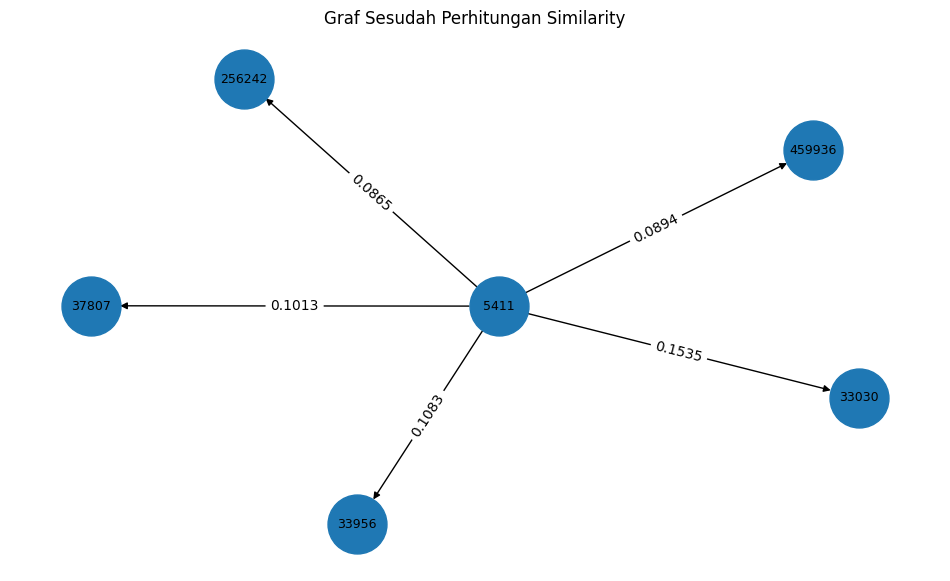

In [59]:
# graf sesudah sim
query = """
MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       r.cosine_similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="uts2") as session:
    result = session.run(query)
    records = [dict(record) for record in result]

G = nx.DiGraph()

for row in records:
    G.add_edge(
        row["item_acuan"],
        row["item_mirip"],
        weight=row["similarity"]
    )

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(12, 7))
nx.draw_networkx(
    G, pos,
    with_labels=True,
    node_size=1800,
    font_size=9,
    arrows=True
)

edge_labels = {
    (u, v): f'{data["weight"]:.4f}'
    for u, v, data in G.edges(data=True)
}

nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)
plt.title("Graf Sesudah Perhitungan Similarity")
plt.axis("off")
plt.show()

1. Kondisi sebelum perhitungan similarity
   text
   ```
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
    RETURN v, r, i
    LIMIT 100;
    ```
2. Kondisi sesudah perhitungan similarity
   text
   ```
   MATCH (a:Item {itemId: 222422})-[r:SIMILAR_TO]->(b:Item)
    RETURN a, r, b
    ORDER BY r.cosine_similarity DESC
    LIMIT 5;

# ANALYTIC

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
   - tuliskan skrip Python dalam merekomendasikan KNN-nya!
   - berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!


In [ ]:

# Pilih Visitor yang layak dievaluasi

import numpy as np
import pandas as pd

jumlah_item_visitor = df_inter.groupby("visitorid")["itemid"].nunique()

# Visitor yang memiliki interaksi di P2
visitor_p2 = set(df_p2["visitorid"].unique())

# Kandidat: minimal 5 Item di training dan muncul di testing
visitor_eligible = [
    v for v, jumlah in jumlah_item_visitor.items()
    if jumlah >= 5 and v in visitor_p2
]

if not visitor_eligible:
    raise ValueError("Tidak ada Visitor yang memenuhi syarat.")

visitor_terpilih = pd.Series(visitor_eligible).sample(
    n=1, random_state=123
).iloc[0]

print("Visitor terpilih:", visitor_terpilih)
print("Jumlah Item unik di training:", jumlah_item_visitor.loc[visitor_terpilih])
print(
    "Jumlah Item unik di testing:",
    df_p2.loc[df_p2["visitorid"] == visitor_terpilih, "itemid"].nunique()
)


Visitor terpilih: 1293432
Jumlah Item unik di training: 6
Jumlah Item unik di testing: 1


In [ ]:

# Riwayat training

riwayat = df_inter.loc[
    df_inter["visitorid"] == visitor_terpilih,
    ["visitorid", "itemid", "weight"]
].copy()

item_kunjung = set(riwayat["itemid"].astype(int))

print("Visitor:", visitor_terpilih)
print("Jumlah baris:", len(riwayat))
print("Jumlah Item unik:", len(item_kunjung))

display(riwayat.head(10))


Visitor: 1293432
Jumlah baris: 6
Jumlah Item unik: 6


,visitorid,itemid,weight
1146305,1293432,61474,2
1146306,1293432,89262,1
1146307,1293432,223203,7
1146308,1293432,281749,2
1146309,1293432,374092,1
1146310,1293432,424515,1


In [ ]:

# KNN Item-Based

k = 5
juml_rekom = 3

skor_rekom = {}

for row in riwayat.itertuples(index=False):
    item_id = int(row.itemid)
    bobot_interaksi = float(row.weight)

    if item_id not in item:
        continue

    idx = item.get_loc(item_id)

    skor = (x_item @ x_item[idx].T).toarray().ravel()
    skor[idx] = -1

    # Hindari Item yang sudah ada di riwayat
    tetangga_idx = np.argsort(skor)[-k:][::-1]

    for j in tetangga_idx:
        kandidat = int(item[j])
        similarity = float(skor[j])

        if kandidat in item_kunjung:
            continue

        skor_rekom[kandidat] = (
            skor_rekom.get(kandidat, 0.0)
            + bobot_interaksi * similarity
        )

hasil_rekomendasi = sorted(
    skor_rekom.items(),
    key=lambda x: x[1],
    reverse=True
)[:juml_rekom]

df_rekomendasi = pd.DataFrame(
    hasil_rekomendasi,
    columns=["item_rekomendasi", "skor_knn"]
)

print("Visitor:", visitor_terpilih)
print("k:", k)
print("Jumlah Item riwayat:", len(item_kunjung))
display(df_rekomendasi)


Visitor: 1293432
k: 5
Jumlah Item riwayat: 6


,item_rekomendasi,skor_knn
0,108308,2.058419
1,347604,1.924902
2,251635,1.924902


pemilihan visitor dilakukan secara acak dan reproducible dengan syarat memiliki minimal lima item unik pada data train dan juga muncul pada data testing.Visitor yang terpilih adalah 1293432, dengan enam Item unik dalam riwayat training.

rekomendasi dibuat menggunakan KNN denga tetangga 5 dan mengukur jarak menggunakan cosine similarity. Skor kandidat dihitung dengan mengakumulasikan kemiripan terhadap Item dalam riwayat Visitor, lalu dikalikan dengan bobot interaksi. 3 Item dengan skor rekomendasi tertinggi adalah Item 108308 dengan skor 2,058419, Item 347604 dengan skor 1,924902, dan Item 251635 dengan skor 1,924902.

2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
   - Hit@5
   - NDCG@5

In [ ]:
# Evaluasi

k_eval = 5

rekomendasi = (
    df_rekomendasi["item_rekomendasi"]
    .head(k_eval)
    .astype(int)
    .tolist()
)

item_relevan = set(
    df_p2.loc[
        df_p2["visitorid"] == visitor_terpilih,
        "itemid"
    ].astype(int)
)

if len(item_relevan) == 0:
    print("Visitor tidak memiliki interaksi di P2.")
    print("Pilih Visitor lain sebelum menghitung metrik.")
else:
    relevance = np.array([
        int(item_id in item_relevan)
        for item_id in rekomendasi
    ])

    hit_at_5 = int(np.sum(relevance) > 0)

    diskon = np.log2(np.arange(2, len(relevance) + 2))
    dcg_at_5 = np.sum(relevance / diskon)

    jumlah_hit = int(np.sum(relevance))
    ideal_relevance = np.array(
        [1] * jumlah_hit + [0] * (len(relevance) - jumlah_hit)
    )

    idcg_at_5 = np.sum(ideal_relevance / diskon)

    ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

    print("Visitor:", visitor_terpilih)
    print("Rekomendasi:", rekomendasi)
    print("Item relevan di P2:", len(item_relevan))
    print("Relevansi:", relevance.tolist())
    print("Hit@5:", hit_at_5)
    print("NDCG@5:", round(float(ndcg_at_5), 4))


Visitor: 1293432
Rekomendasi: [108308, 347604, 251635]
Item relevan di P2: 1
Relevansi: [0, 0, 0]
Hit@5: 0
NDCG@5: 0.0


In [ ]:

# Periksa konsistensi hasil

print("Visitor:", visitor_terpilih)
print("Rekomendasi:")
display(df_rekomendasi)

print("\nPemeriksaan setiap rekomendasi:")
item_p2 = set(df_p2["itemid"].astype(int))
item_relevan = set(
    df_p2.loc[
        df_p2["visitorid"] == visitor_terpilih,
        "itemid"
    ].astype(int)
)

for item_id in df_rekomendasi["item_rekomendasi"].astype(int):
    print(
        f"Item {item_id}: ada di P2 = {item_id in item_p2}, "
        f"relevan untuk Visitor = {item_id in item_relevan}"
    )


Visitor: 1293432
Rekomendasi:


,item_rekomendasi,skor_knn
0,108308,2.058419
1,347604,1.924902
2,251635,1.924902



Pemeriksaan setiap rekomendasi:
Item 108308: ada di P2 = False, relevan untuk Visitor = False
Item 347604: ada di P2 = True, relevan untuk Visitor = False
Item 251635: ada di P2 = False, relevan untuk Visitor = False


In [ ]:

# Evaluasi KNN pada 100 Visitor

from collections import Counter

# Kandidat Visitor dengan minimal 5 Item training
jumlah_train = df_inter.groupby("visitorid")["itemid"].nunique()
jumlah_test = df_p2.groupby("visitorid")["itemid"].nunique()

visitor_eligible = [
    v for v in jumlah_train.index
    if jumlah_train.loc[v] >= 5
    and v in jumlah_test.index
    and jumlah_test.loc[v] > 0
]

# Sampel yang reproducible
sample_size = min(100, len(visitor_eligible))
visitor_sample = pd.Series(visitor_eligible).sample(
    n=sample_size, random_state=123
).tolist()

hasil_evaluasi = []

for visitor in visitor_sample:
    hist = df_inter[df_inter["visitorid"] == visitor]
    seen = set(hist["itemid"].astype(int))
    scores = {}

    for row in hist.itertuples(index=False):
        item_id = int(row.itemid)

        if item_id not in item:
            continue

        idx = item.get_loc(item_id)
        sim = (x_item @ x_item[idx].T).toarray().ravel()
        sim[idx] = -1

        neighbors = np.argsort(sim)[-5:][::-1]

        for j in neighbors:
            candidate = int(item[j])

            if candidate in seen:
                continue

            scores[candidate] = (
                scores.get(candidate, 0.0)
                + float(row.weight) * float(sim[j])
            )

    recs = [
        item_id
        for item_id, _ in sorted(
            scores.items(),
            key=lambda x: x[1],
            reverse=True
        )[:3]
    ]

    relevant = set(
        df_p2.loc[
            df_p2["visitorid"] == visitor, "itemid"
        ].astype(int)
    )

    rel = np.array([int(r in relevant) for r in recs])
    hit = int(rel.sum() > 0)

    discounts = np.log2(np.arange(2, len(rel) + 2))
    dcg = np.sum(rel / discounts)
    ideal = np.sort(rel)[::-1]
    idcg = np.sum(ideal / discounts)

    ndcg = float(dcg / idcg) if idcg > 0 else 0.0

    hasil_evaluasi.append({
        "visitorid": visitor,
        "jumlah_relevan_p2": len(relevant),
        "rekomendasi": recs,
        "Hit@5": hit,
        "NDCG@5": ndcg
    })

df_evaluasi = pd.DataFrame(hasil_evaluasi)

print("Jumlah Visitor dievaluasi:", len(df_evaluasi))
print("Rata-rata Hit@5:", df_evaluasi["Hit@5"].mean())
print("Rata-rata NDCG@5:", df_evaluasi["NDCG@5"].mean())
print(
    "Visitor dengan minimal satu rekomendasi relevan:",
    int(df_evaluasi["Hit@5"].sum())
)

display(df_evaluasi.head(10))


Jumlah Visitor dievaluasi: 100
Rata-rata Hit@5: 0.01
Rata-rata NDCG@5: 0.005
Visitor dengan minimal satu rekomendasi relevan: 1


,visitorid,jumlah_relevan_p2,rekomendasi,Hit@5,NDCG@5
0,1293432,1,"[108308, 347604, 251635]",0,0.0
1,304701,1,"[360550, 119433, 308964]",0,0.0
2,1103914,14,"[160949, 430300, 231407]",0,0.0
3,331366,10,"[38115, 234618, 111101]",0,0.0
4,1385808,1,"[180002, 167985, 198503]",0,0.0
5,134685,4,"[352826, 44795, 322927]",0,0.0
6,1198235,2,"[228491, 87892, 58710]",0,0.0
7,1218580,6,"[53452, 328205, 283652]",0,0.0
8,66643,2,"[381310, 333019, 30681]",0,0.0
9,123038,1,"[396478, 419690, 68558]",0,0.0


In [ ]:

# Periksa Visitor yang mendapat rekomendasi relevan

visitor_hit = df_evaluasi[df_evaluasi["Hit@5"] == 1]

print("Jumlah Visitor yang mendapat hit:", len(visitor_hit))

display(visitor_hit)

# Periksa apakah rekomendasi berada di P1 dan P2
item_p1 = set(df_inter["itemid"].astype(int))
item_p2 = set(df_p2["itemid"].astype(int))

for row in visitor_hit.itertuples(index=False):
    print("\nVisitor:", row.visitorid)
    print("Item relevan di P2:",
          set(df_p2.loc[
              df_p2["visitorid"] == row.visitorid, "itemid"
          ].astype(int)))
    print("Rekomendasi:", row.rekomendasi)

    for item_id in row.rekomendasi:
        print(
            f"Item {item_id}:",
            "ada di P1 =", item_id in item_p1,
            "| ada di P2 =", item_id in item_p2
        )


Jumlah Visitor yang mendapat hit: 1


,visitorid,jumlah_relevan_p2,rekomendasi,Hit@5,NDCG@5
73,897679,14,"[37115, 252319, 38965]",1,0.5



Visitor: 897679
Item relevan di P2: {319680, 239006, 163495, 82377, 412622, 241555, 444948, 381941, 9877, 38965, 44826, 103003, 82173, 325310}
Rekomendasi: [37115, 252319, 38965]
Item 37115: ada di P1 = True | ada di P2 = True
Item 252319: ada di P1 = True | ada di P2 = True
Item 38965: ada di P1 = True | ada di P2 = True


Evaluasi dilakukan dengan membandingkan Item hasil rekomendasi terhadap Item yang benar-benar diinteraksikan oleh Visitor pada periode testing P2. Untuk Visitor 1293432, rekomendasi yang dihasilkan adalah Item 108308, 347604, dan 251635. tidak ada satupun ddari item tersebut yang termasuk ke dalam interaksi visitor pada P@, sehingga vektor relevansinya adalah [0 0 0]. sehingga menghasilkan evaluasi menghasilkan Hit@5 sebesar 0 dan NDCG@5 sebesar 0.

evaluasi selanjutnya dilakukan terhadap 100 visitor yang dipilih secara reproducible. hasilnya naik dari seblumnya dengat rata rata Hit@5 sebesar 0,01 dan rata-rata NDCG@5 sebesar 0,005(Hanya satu Visitor yang memperoleh setidaknya satu rekomendasi relevan, yaitu Visitor 897679). item 38965 muncul pada peringkat ketiga dan relevan terhadap interaksi Visitor tersebut pada P2, menghasilkan Hit@5 sebesar 1 dan NDCG@5 sebesar 0,5.

38965 muncul pada peringkat ketiga dan relevan terhadap interaksi Visitor tersebut pada P2, menghasilkan Hit@5 sebesar 1 dan NDCG@5 sebesar 0,5.

Hasil tersebut menunjukkan bahwa pada pengujian yang dilakukan, hanya sebagian kecil rekomendasi yang sesuai dengan interaksi aktual Visitor pada periode testing. Interpretasi metrik perlu memperhatikan bahwa implementasi saat ini menghasilkan tiga rekomendasi per Visitor, sehingga evaluasi mencakup maksimal tiga posisi rekomendasi yang tersedia.